# willmarley: choosing a motor, propeller, and battery

Tracks [issue #85](https://github.com/MarMar888/hav/issues/85).

We have three things to buy: a motor, a propeller and a battery. Each gets a section with its
equations, its inputs, and a low/high range for every input. Nothing is chosen at the very start. Some numbers are
consequences of the others (pack size, pack discharge rating, prop pitch). The model prints those
as shopping notes instead of treating them as choices.

The battery's weight counts against the boat, the water's resistance is part of the solve, and the
speed that comes out is the speed where thrust and resistance balance.

The chain:

> **battery** gives volts and amps (and adds its own weight) → **motors** turn them into torque
> and rpm → **propeller** turns shaft power into pull, never more than its disk can give →
> **water** pushes back, more with weight and more with speed → speed is where pull and
> push-back balance.

Section 5 draws this as a map. Every number below is computed from the ranges, so you can edit
any bound and re-run.

In [43]:
import csv
import math
from collections import Counter

import matplotlib.pyplot as plt
import numpy as np

# Constants and unit conversions
RHO = 999.0          # water density, kg/m^3
M_PER_IN = 0.0254 # just conversions
N_PER_LBF = 4.4482
MPS_PER_MPH = 0.44704
G_PER_LB = 453.592
PITCH_UNITS = 1056   # in/min per mph, so pitch (in) = speed (mph) * 1056 / rpm

# Chart colors
LIGHT_BLUE, MID_BLUE, DARK_BLUE = "#9ecae1", "#4292c6", "#08519c"
SEQ = [LIGHT_BLUE, MID_BLUE, DARK_BLUE]  # low / mid / high of one input, light to dark
BAND_GRAY = "#eceae5"
INVALID_GRAY = "#d8d6cf"
TEXT = "#1a1a19"
MUTED = "#8a887f"


def mid(bounds, key):
    lo, hi = bounds[key]
    return (lo + hi) / 2


def lo_mid_hi(bounds, key):
    lo, hi = bounds[key]
    return [lo, (lo + hi) / 2, hi]


def show_bounds(bounds, units):
    """Print the low/high table for a group of inputs."""
    w = max(len(k) for k in bounds)
    print(f"{'input':<{w}}  {'low':>7}  {'high':>7}  unit")
    for k, (lo, hi) in bounds.items():
        print(f"{k:<{w}}  {lo:>7g}  {hi:>7g}  {units[k]}")


def label_end(ax, x, y, text, color):
    """Write a label just to the right of the end of a line."""
    ax.annotate(text, (x, y), xytext=(5, 0), textcoords="offset points", color=color, va="center")


def range_bar(ax, y, q10, q50, q90):
    """One row of a range chart: gray = the full input range, blue = p10 to p90, dot = median."""
    ax.barh(y, 1.0, left=0, height=0.62, color=BAND_GRAY, zorder=1)
    ax.barh(y, q90 - q10, left=q10, height=0.62, color=LIGHT_BLUE, zorder=2)
    ax.plot(q50, y, "o", color=DARK_BLUE, ms=7, zorder=3)

## 1. The motor

A DC motor is described by two numbers, `Kv` and `R`, plus two limits, `I0` and `I_max`.

```text
Kt  = 60 / (2π · Kv)        torque constant: N·m per amp
Q   = Kt · (I − I0)         torque out for current in (I0 is lost to friction)
rpm = Kv · (V − I · R)      speed for volts in (I·R is lost in the winding)
I  ≤ I_max                  current limit: more amps than this damages the motor
```

`Kv` is a trade-off. A high-Kv motor spins faster per volt but makes less torque per amp. The
product `Kt · Kv` is always 60/2π, so you can't improve both.

A motor also has a weight (`W_motor`), which the boat carries (section 4). `n_motors` (1 or 2) is
the number of motors. Two motors double the shaft power, the motor weight and the current drawn
from the pack, and each motor turns its own prop.

### How many volts does a motor need?

Rearranging the speed equation:

```text
rpm = Kv · (V − I·R)      ->      V_needed  =  rpm / Kv  +  I · R
                                              back-EMF     winding loss
```

A spinning motor also acts as a generator. It pushes back against the pack with `rpm / Kv`
volts (the back-EMF). The pack only has to beat that, plus the small `I·R` loss. The propeller
load sets the rpm (section 6 solves it). Extra volts do not spin a loaded motor faster. They
only push more current through it, and current above `I_max` is not allowed anyway. So:

- Pack voltage is sized by the operating point, the rpm the prop load settles at.
- The winding's rated `v_max` is a ceiling, not a requirement. On the SSS sheet it is
  `max_rpm / Kv`, the no-load spin limit.
- A low-Kv motor held back by a big prop can run on a small pack.

The chart below draws `V_needed`. The shopping lists in section 10 print it next to the pack
each ideal design chose.

In [44]:
MOTOR_BOUNDS = { # THESE ARE HARDCODED UPPER AND LOWER BOUNDS
    "Kv":       (300.0, 1200.0),
    "R":        (0.005, 0.050),
    "I0":       (1.0, 6.0),
    "I_max":    (50.0, 320.0),
    "W_motor":  (0.4, 5.0),
    "n_motors": (1, 2),
}
MOTOR_UNITS = {"Kv": "rpm/V", "R": "ohm", "I0": "A", "I_max": "A", "W_motor": "lb", "n_motors": "-"}
show_bounds(MOTOR_BOUNDS, MOTOR_UNITS)

# Mid-range values for the example charts
I0_mid = mid(MOTOR_BOUNDS, "I0")
Imax_mid = mid(MOTOR_BOUNDS, "I_max")
R_mid = mid(MOTOR_BOUNDS, "R")

input         low     high  unit
Kv            300     1200  rpm/V
R           0.005     0.05  ohm
I0              1        6  A
I_max          50      320  A
W_motor       0.4        5  lb
n_motors        1        2  -


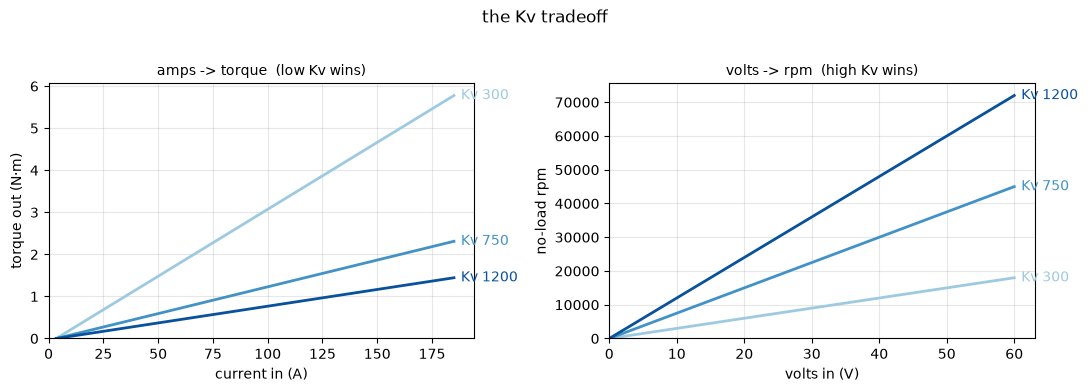

In [45]:
# Left: torque vs amps. Right: no-load rpm vs volts. Both for low, mid and high Kv.
amps = np.linspace(I0_mid, Imax_mid, 50)
volts = np.linspace(0, 60, 2)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 3.8))
for Kv, color in zip(lo_mid_hi(MOTOR_BOUNDS, "Kv"), SEQ):
    Kt = 60 / (2 * math.pi * Kv)
    torque = Kt * (amps - I0_mid)
    ax1.plot(amps, torque, color=color, lw=2)
    label_end(ax1, amps[-1], torque[-1], f"Kv {Kv:g}", color)

    no_load_rpm = Kv * volts
    ax2.plot(volts, no_load_rpm, color=color, lw=2)
    label_end(ax2, volts[-1], no_load_rpm[-1], f"Kv {Kv:g}", color)

ax1.set_xlabel("current in (A)"); ax1.set_ylabel("torque out (N·m)")
ax1.set_title("amps -> torque  (low Kv wins)", fontsize=10)
ax2.set_xlabel("volts in (V)"); ax2.set_ylabel("no-load rpm")
ax2.set_title("volts -> rpm  (high Kv wins)", fontsize=10)
for ax in (ax1, ax2):
    ax.grid(alpha=0.3); ax.set_xlim(left=0); ax.set_ylim(bottom=0)
    ax.margins(x=0.15)
fig.suptitle("the Kv tradeoff", y=1.02)
plt.tight_layout(); plt.show()

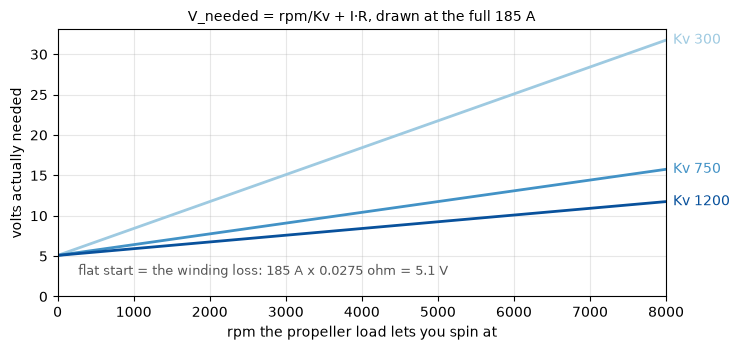

In [46]:
# Volts needed vs the rpm the prop load allows, at the full I_max
rpm_axis = np.linspace(0, 8000, 100)
winding_loss = Imax_mid * R_mid

fig, ax = plt.subplots(figsize=(7.5, 3.6))
for Kv, color in zip(lo_mid_hi(MOTOR_BOUNDS, "Kv"), SEQ):
    V_need = rpm_axis / Kv + winding_loss
    ax.plot(rpm_axis, V_need, color=color, lw=2)
    label_end(ax, rpm_axis[-1], V_need[-1], f"Kv {Kv:g}", color)
ax.annotate(f"flat start = the winding loss: {Imax_mid:g} A x {R_mid:g} ohm = {winding_loss:.1f} V",
            (rpm_axis[2], winding_loss), xytext=(6, -14), textcoords="offset points",
            fontsize=9, color="#555555")
ax.set_xlabel("rpm the propeller load lets you spin at")
ax.set_ylabel("volts actually needed")
ax.set_title(f"V_needed = rpm/Kv + I·R, drawn at the full {Imax_mid:g} A", fontsize=10)
ax.grid(alpha=0.3); ax.set_xlim(0, rpm_axis[-1]); ax.set_ylim(bottom=0)
ax.margins(x=0.15)
plt.tight_layout(); plt.show()

## 2. The propeller

Four equations: the load the prop puts on the motor, the most thrust its disk can give, how well
it turns power into pull, and the pitch to buy.

```text
Q        = K_Q · ρ · n² · D⁵          torque the water demands to spin it
                                      (n in rev/s, D in meters, ρ = water density)
T        = K_T · ρ · n² · D⁴          the most thrust this disk can give at that rpm
P_pull   = η_p · P_shaft              pull power, from shaft power
pitch    = speed · 1056 / (rpm · 0.8) pitch to buy, sized so the prop runs at ~80%
                                      of its pitch speed (1056 converts in/min -> mph)
```

The inputs:

- **D (diameter)** sets the load. It enters to the 5th power, so a small change in diameter
  changes the torque demand a lot.
- **K_Q** is the torque coefficient, one constant per prop. It comes from the propeller's measured
  curve (model-basin series data). On a real prop it rises with pitch. Right now its IDP
- **K_T** is the thrust coefficient, how hard the disk can push at a given rpm. 
- **η_p** is the prop efficiency, the fraction of shaft power that becomes pull. It also comes
  from the prop's curve. Good props on plane are roughly 0.5–0.7.
- **pitch** Once the solve knows the rpm and the speed, the pitch to buy
  follows (at a fixed ~80% of pitch speed)

In [47]:
PROP_BOUNDS = {
    "K_Q":   (0.02, 0.05), # THIS CAN prolly just be fixed
    "K_T":   (0.05, 0.15), # Thrust coefficient
    "D_in":  (2.0, 7.0),
    "eta_p": (0.5, 0.7),
}
PROP_UNITS = {"K_Q": "-", "K_T": "-", "D_in": "in", "eta_p": "-"}
show_bounds(PROP_BOUNDS, PROP_UNITS)

SLIP_TARGET = 0.80           # run the prop at ~80% of its pitch speed
PITCH_BUYABLE = (6.0, 14.0)  # pitches you can actually buy, inches
print(f"fixed: pitch is actually just a calculated value, not chosen -- speed x 1056 / (rpm x {SLIP_TARGET:g}), "
      f"must land in {PITCH_BUYABLE[0]:g}-{PITCH_BUYABLE[1]:g} in")

input      low     high  unit
K_Q       0.02     0.05  -
K_T       0.05     0.15  -
D_in         2        7  in
eta_p      0.5      0.7  -
fixed: pitch is actually just a calculated value, not chosen -- speed x 1056 / (rpm x 0.8), must land in 6-14 in


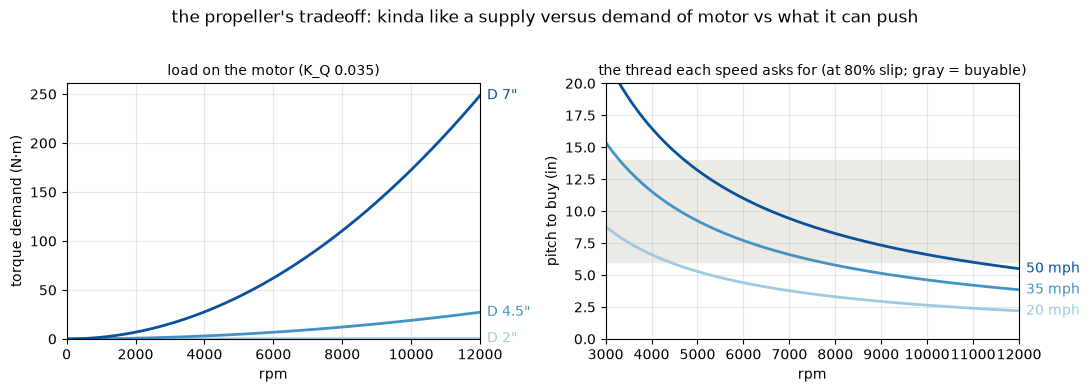

In [48]:
# Left: torque the prop demands vs rpm. Right: pitch each speed asks for.
KQ_mid = mid(PROP_BOUNDS, "K_Q")
rpm_axis = np.linspace(0, 12000, 200)
rpm_axis_pitch = np.linspace(3000, 12000, 200)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 3.8))
for D_in, color in zip(lo_mid_hi(PROP_BOUNDS, "D_in"), SEQ):
    Q = KQ_mid * RHO * (rpm_axis / 60) ** 2 * (D_in * M_PER_IN) ** 5
    ax1.plot(rpm_axis, Q, color=color, lw=2)
    label_end(ax1, rpm_axis[-1], Q[-1], f'D {D_in:g}"', color)

ax2.axhspan(*PITCH_BUYABLE, color=BAND_GRAY, zorder=0)
for speed, color in zip((20.0, 35.0, 50.0), SEQ):
    pitch = speed * PITCH_UNITS / (rpm_axis_pitch * SLIP_TARGET)
    ax2.plot(rpm_axis_pitch, pitch, color=color, lw=2)
    label_end(ax2, rpm_axis_pitch[-1], pitch[-1], f"{speed:g} mph", color)

ax1.set_xlabel("rpm"); ax1.set_ylabel("torque demand (N·m)")
ax1.set_title(f"load on the motor (K_Q {KQ_mid:g})", fontsize=10)
ax2.set_xlabel("rpm"); ax2.set_ylabel("pitch to buy (in)")
ax2.set_title(f"the thread each speed asks for (at {SLIP_TARGET:.0%} slip; gray = buyable)", fontsize=10)
ax1.grid(alpha=0.3); ax1.set_xlim(0, rpm_axis[-1]); ax1.set_ylim(bottom=0); ax1.margins(x=0.15)
ax2.grid(alpha=0.3); ax2.set_xlim(rpm_axis_pitch[0], rpm_axis_pitch[-1]); ax2.set_ylim(0, 20); ax2.margins(x=0.15)
fig.suptitle("the propeller's tradeoff: kinda like a supply versus demand of motor vs what it can push", y=1.02)
plt.tight_layout(); plt.show()

## 3. The battery

The battery brings volts, amp-hours and its own weight, which the boat has to carry.

```text
P_elec        = V · I                                  watts drawn from the pack
C_needed      = I · (course/speed) · reserve / 0.8     amp-hours the race requires
W_batt        = C · V / e_batt                         pack weight (e_batt in Wh/lb)
C_rate_needed = I / (0.8 · C)                          discharge rating the pack must carry
```

Only two battery numbers are decisions: pack voltage `V` and specific energy `e_batt` (chemistry
quality). Capacity and discharge rating are requirements that the design writes on the shopping
list. The race sets the amp-hours (the usable fraction is fixed at 0.8 as policy, not an input),
and the amps set the C-rating. Each has one limit on what you can buy.

Capacity and weight depend on each other. A bigger pack is heavier, a heavier boat is slower, and
a slower boat takes longer to race and needs more pack. The solve iterates this to a fixed
point. There is no free capacity: every amp-hour is carried through the water.

In [49]:
BATT_BOUNDS = {
    "V":      (20.0, 50.0),
    "e_batt": (50.0, 100.0),
}
BATT_UNITS = {"V": "V", "e_batt": "Wh/lb"}
show_bounds(BATT_BOUNDS, BATT_UNITS)

USABLE = 0.8            # how deep we discharge: policy, not an input
DISCHARGE_DERATE = 0.8  # the steady draw should sit at ~80% of the pack's rating
C_RATE_MAX = 10.0       # hottest pack we consider buyable (continuous C-rating)
RACE = {"miles": 5.0, "reserve": 1.3}  # the race that sizes every pack. EDIT to the real course.
print(f"fixed: usable {USABLE:g}; rating needed = amps/({DISCHARGE_DERATE:g} x C) <= {C_RATE_MAX:g}C")
print(f"race: {RACE['miles']:g} mi at constant drive, +{RACE['reserve'] - 1:.0%} energy reserve")

input       low     high  unit
V            20       50  V
e_batt       50      100  Wh/lb
fixed: usable 0.8; rating needed = amps/(0.8 x C) <= 10C
race: 5 mi at constant drive, +30% energy reserve


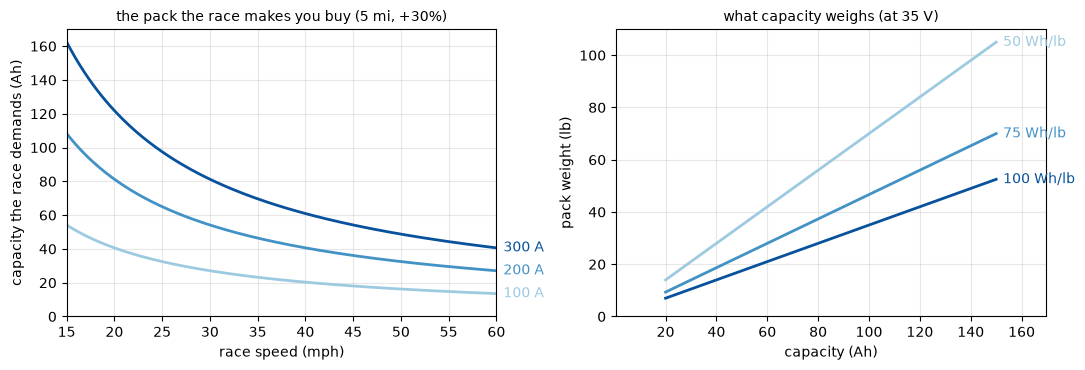

In [50]:
# Left: capacity the race demands. Right: what that capacity weighs.
V_mid = mid(BATT_BOUNDS, "V")
v_axis = np.linspace(15, 60, 200)
capacity_axis = np.linspace(20, 150, 100)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 3.8))
for I_draw, color in zip((100.0, 200.0, 300.0), SEQ):
    C_need = I_draw * RACE["miles"] / v_axis * RACE["reserve"] / USABLE
    ax1.plot(v_axis, C_need, color=color, lw=2)
    label_end(ax1, v_axis[-1], C_need[-1], f"{I_draw:g} A", color)

for e, color in zip(lo_mid_hi(BATT_BOUNDS, "e_batt"), SEQ):
    pack_lb = capacity_axis * V_mid / e
    ax2.plot(capacity_axis, pack_lb, color=color, lw=2)
    label_end(ax2, capacity_axis[-1], pack_lb[-1], f"{e:g} Wh/lb", color)

ax1.set_xlabel("race speed (mph)"); ax1.set_ylabel("capacity the race demands (Ah)")
ax1.set_title(f"the pack the race makes you buy ({RACE['miles']:g} mi, +{RACE['reserve'] - 1:.0%})",
              fontsize=10)
ax2.set_xlabel("capacity (Ah)"); ax2.set_ylabel("pack weight (lb)")
ax2.set_title(f"what capacity weighs (at {V_mid:g} V)", fontsize=10)
for ax in (ax1, ax2):
    ax.grid(alpha=0.3); ax.set_ylim(bottom=0)
ax1.set_xlim(v_axis[0], v_axis[-1]); ax1.margins(x=0.15); ax2.margins(x=0.15)
plt.tight_layout(); plt.show()

## 4. The water and the weight

On plane, the water's resistance is the all-up weight divided by the hull's lift-to-drag ratio
(L/D):

```text
W        = W_hull + W_batt + n_motors·W_motor + payload + margin    all-up weight
L/D(v)   = LD0 / (1 + (v / 26)²)                                    L/D falls as speed rises
R_water  = W / L/D(v)                                               resistance on plane, lbf
P_tow    = R_water · speed                                          power needed to tow the boat
```

`W_hull` is the bare hull (structure and fittings only). The boat also carries the pack
(`W_batt`), the motors (`W_motor` each), a fixed payload we are required to haul, and a safety
margin. The payload and margin are constants, set and printed below.

L/D is not constant. Skin friction grows with speed², so a hull at L/D ≈ 6 just after planing is
down near 2.5 when driven hard. The curve has one quality input, `LD0` (the hull's peak L/D), and
one fixed shape constant (26 mph, the speed where friction has doubled the resistance). Both were
calibrated against the Savitsky planing model in the archived explore notebook. Because
resistance grows with speed on its own, the model needs no artificial speed cap.

In [51]:
HULL_BOUNDS = {
    "W_hull": (30.0, 90.0),
    "LD0":    (5.0, 10.0),
}
HULL_UNITS = {"W_hull": "lb", "LD0": "-"}
show_bounds(HULL_BOUNDS, HULL_UNITS)

V_LD_HALF = 26.0  # mph at which friction has doubled the resistance (Savitsky cross-check)
print(f"fixed: L/D(v) = LD0 / (1 + (v/{V_LD_HALF:g})^2)")

W_FIXED = {"payload": 30.0, "safety margin": 5.0}  # lb, carried no matter what
W_FIXED_LB = sum(W_FIXED.values())
for name, weight in W_FIXED.items():
    print(f"fixed: {name:<14}{weight:>7g}  lb")

input       low     high  unit
W_hull       30       90  lb
LD0           5       10  -
fixed: L/D(v) = LD0 / (1 + (v/26)^2)
fixed: payload            30  lb
fixed: safety margin       5  lb


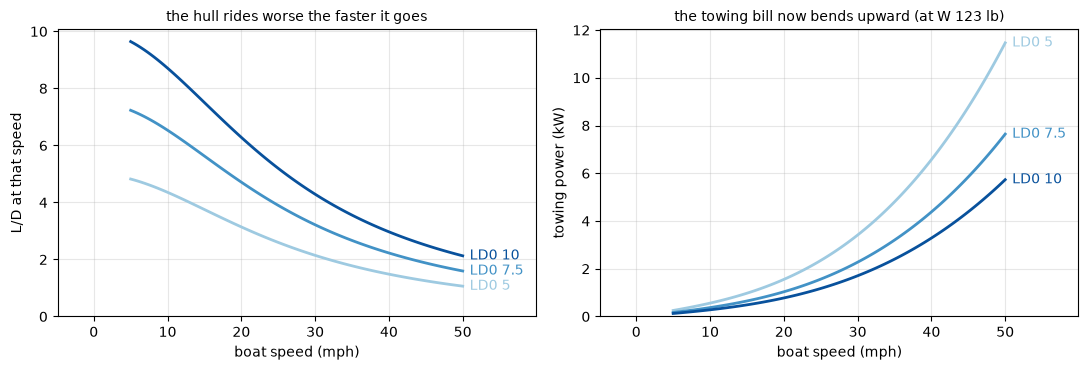

In [52]:
# Left: L/D vs speed. Right: towing power vs speed. Both for low, mid and high LD0.
W_batt_example = 25.0  # a typical race-sized pack, only for the weight in this chart
W_extra = W_batt_example + mid(MOTOR_BOUNDS, "W_motor") + W_FIXED_LB
W_span = np.linspace(HULL_BOUNDS["W_hull"][0] + W_extra,
                     HULL_BOUNDS["W_hull"][1] + W_extra, 100)
W_mid = W_span.mean()

v = np.linspace(5, 50, 100)
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 3.8))
for LD0, color in zip(lo_mid_hi(HULL_BOUNDS, "LD0"), SEQ):
    LD = LD0 / (1 + (v / V_LD_HALF) ** 2)
    ax1.plot(v, LD, color=color, lw=2)
    label_end(ax1, v[-1], LD[-1], f"LD0 {LD0:g}", color)

    R_N = (W_mid / LD) * N_PER_LBF
    tow_kw = R_N * v * MPS_PER_MPH / 1000
    ax2.plot(v, tow_kw, color=color, lw=2)
    label_end(ax2, v[-1], tow_kw[-1], f"LD0 {LD0:g}", color)

ax1.set_xlabel("boat speed (mph)"); ax1.set_ylabel("L/D at that speed")
ax1.set_title("the hull rides worse the faster it goes", fontsize=10)
ax2.set_xlabel("boat speed (mph)"); ax2.set_ylabel("towing power (kW)")
ax2.set_title(f"the towing bill now bends upward (at W {W_mid:.0f} lb)", fontsize=10)
for ax in (ax1, ax2):
    ax.grid(alpha=0.3); ax.set_ylim(bottom=0)
    ax.margins(x=0.22)
plt.tight_layout(); plt.show()

## 5. The map: how everything connects

One picture of the whole model. The left column lists every input, colored by the purchase (or
the hull) it belongs to. The middle column has the quantities the equations build from them. The
right column has the results. Every arrow is one of the equations above.

Two things to notice. `V` feeds two paths: volts set the rpm, and volts also set the weight of
the pack. And the pack is sized by the race (amps × race time), but its weight changes the speed,
which changes the race time. The solve iterates that pair to a fixed point.

In [53]:
GROUP_COLORS = {"battery": "#2a78d6", "motor": "#eb6834", "prop": "#1baf7a", "hull": "#eda100"}
LABELS = {  # long name for every short input symbol
    "V": "pack voltage", "e_batt": "specific energy",
    "Kv": "speed constant", "R": "winding resistance", "I0": "no-load current", "I_max": "current limit",
    "K_Q": "torque coefficient", "K_T": "thrust coefficient", "D_in": "diameter", "pitch": "blade pitch",
    "eta_p": "prop efficiency",
    "W_hull": "bare hull weight", "LD0": "peak lift-to-drag", "W_motor": "motor weight",
    "n_motors": "number of motors",
}
INPUT_GROUPS = [
    ("battery", list(BATT_BOUNDS)),
    ("motor",   list(MOTOR_BOUNDS)),
    ("prop",    list(PROP_BOUNDS)),
    ("hull",    list(HULL_BOUNDS)),
]

# Middle and output boxes
TB = "torque balance\n(rpm, amps, shaft watts)"
PACK = "pack the race requires\n(Ah, lb, C-rate)"
WEIGHT = "all-up weight (W)"
PUSHBACK = "water push-back (R_water)"
FIXED_NODE = f"payload + margin (fixed {W_FIXED_LB:g} lb)"

MID_NODES = {PACK: 15.0, WEIGHT: 12.6, PUSHBACK: 10.2, TB: 5.0}  # name: y
OUT_NODES = {"speed": 8.0, "runtime": 2.0}                       # name: y
HALF_WIDTH = {  # half-widths of the middle and output boxes, so arrows stop at the edge
    PACK: 0.52, WEIGHT: 0.36, PUSHBACK: 0.45, TB: 0.42, "speed": 0.20, "runtime": 0.24,
}

# One arrow per equation, in drawing order
EDGES = [
    ("V", PACK), ("e_batt", PACK), (TB, PACK),
    ("W_hull", WEIGHT), (PACK, WEIGHT), ("W_motor", WEIGHT),
    (WEIGHT, PUSHBACK), ("LD0", PUSHBACK),
    ("Kv", TB), ("R", TB), ("I0", TB), ("I_max", TB), ("V", TB), ("K_Q", TB), ("D_in", TB),
    ("n_motors", TB), ("n_motors", WEIGHT),
    (TB, "speed"), ("eta_p", "speed"), (PUSHBACK, "speed"), ("K_T", "speed"),
    (TB, "runtime"), (PACK, "runtime"),
    (FIXED_NODE, WEIGHT),
]

# Positions: inputs stacked in the left column, then the middle and output columns
pos = {}
y = 18.3
for group, keys in INPUT_GROUPS:
    for k in keys:
        pos[k] = (0.0, y)
        y -= 1.0
    y -= 0.7  # gap between groups
pos[FIXED_NODE] = (0.0, y)
for name, node_y in MID_NODES.items():
    pos[name] = (1.55, node_y)
for name, node_y in OUT_NODES.items():
    pos[name] = (3.1, node_y)

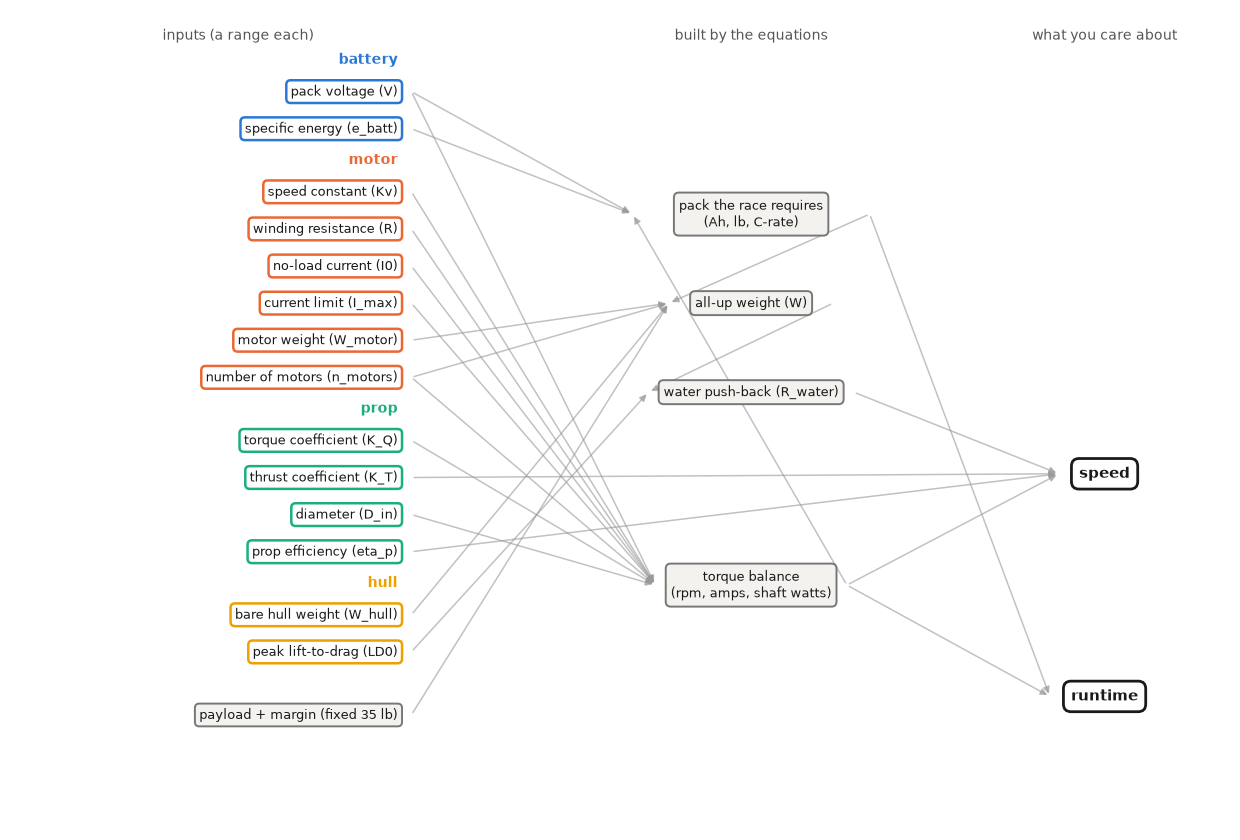

In [54]:
fig, ax = plt.subplots(figsize=(12.5, 8.5))

for a, b in EDGES:
    (xa, ya), (xb, yb) = pos[a], pos[b]
    x_start = xa + HALF_WIDTH.get(a, 0.06)
    ax.annotate("", xy=(xb - HALF_WIDTH[b], yb), xytext=(x_start, ya),
                arrowprops=dict(arrowstyle="-|>", color="#999999", alpha=0.6, lw=1.1))

for group, keys in INPUT_GROUPS:
    color = GROUP_COLORS[group]
    top = max(pos[k][1] for k in keys)
    ax.text(0.0, top + 0.75, group, color=color, fontsize=10, fontweight="bold", ha="right")
    for k in keys:
        ax.text(*pos[k], f"{LABELS[k]} ({k})", ha="right", va="center", fontsize=9, color=TEXT,
                bbox=dict(boxstyle="round,pad=0.35", fc="white", ec=color, lw=1.8))

ax.text(*pos[FIXED_NODE], FIXED_NODE, ha="right", va="center", fontsize=9, color=TEXT,
        bbox=dict(boxstyle="round,pad=0.35", fc="#f3f2ee", ec="#777777", lw=1.4))
for name in MID_NODES:
    ax.text(*pos[name], name, ha="center", va="center", fontsize=9, color=TEXT,
            bbox=dict(boxstyle="round,pad=0.4", fc="#f3f2ee", ec="#777777", lw=1.4))
for name in OUT_NODES:
    ax.text(*pos[name], name, ha="center", va="center", fontsize=11, color=TEXT, fontweight="bold",
            bbox=dict(boxstyle="round,pad=0.5", fc="white", ec=TEXT, lw=2))

ax.text(-0.7, 19.7, "inputs (a range each)", ha="center", fontsize=10, color="#555555")
ax.text(1.55, 19.7, "built by the equations", ha="center", fontsize=10, color="#555555")
ax.text(3.1, 19.7, "what you care about", ha="center", fontsize=10, color="#555555")
ax.set_xlim(-1.7, 3.65); ax.set_ylim(-1.6, 20.5); ax.axis("off")
plt.tight_layout(); plt.show()

## 6. Bring it together

The solve runs in the order the physics goes:

```text
1  torque balance    a·rpm² + b·rpm = c  ->  rpm, amps, torque (per motor)
                     a = K_Q·ρ·D⁵/3600,  b = Kt/(Kv·R),  c = Kt·(V/R − I0)
                     (if amps exceed I_max: torque is held at its I_max value and the rpm
                     comes from the prop alone)
2  shaft power       P_shaft = n_motors · torque · 2π · rpm / 60
3  the fixed point   the race sets the pack size, the pack adds weight, the weight slows the
                     boat, and a slower boat needs more pack. Iterate until it settles:
                       W      =  W_hull + W_batt + n_motors·W_motor + payload + margin
                       speed  from  η_p · P_shaft = R_water(speed) · speed   (cubic, one root)
                       C      =  amps · (course/speed) · reserve / 0.8
4  thrust check      n_motors·K_T·ρ·n²·D⁴ ≥ R_water(speed)  -- can the disks deliver it?
5  shopping notes    pitch = speed·1056/(rpm·0.8),  C_rate = amps/(0.8·C),  W_batt = C·V/e_batt
```

No design point is picked or printed here. The charts below show the whole space.

In [55]:
BOUNDS = {**MOTOR_BOUNDS, **PROP_BOUNDS, **BATT_BOUNDS, **HULL_BOUNDS}
UNITS = {**MOTOR_UNITS, **PROP_UNITS, **BATT_UNITS, **HULL_UNITS}
CENTER = {k: (lo + hi) / 2 for k, (lo, hi) in BOUNDS.items()}  # mid-range reference for the sweeps
CENTER["n_motors"] = 1.0  # the sweeps and example charts use a single motor

# Settings for the pack-sizing loop
CAPACITY_START_AH = 50.0
CAPACITY_MAX_AH = 400.0
SPEED_FLOOR_MPH = 2.0   # keeps the race time finite when the boat is nearly stopped
MAX_ITERATIONS = 25
TOLERANCE_AH = 0.05


def cbrt(x):
    """Real cube root, also for negative x."""
    return math.copysign(abs(x) ** (1 / 3), x)


def motor_prop_balance(Kv, R, I0, I_max, V, K_Q, D_in):
    """Find where one motor's torque equals the prop's torque demand.

    Returns rpm, amps, torque, and whether the motor is held at its current limit.
    """
    Kt = 60 / (2 * math.pi * Kv)
    prop_load = K_Q * RHO * (D_in * M_PER_IN) ** 5  # prop torque = prop_load * (rpm / 60)**2
    a = prop_load / 3600
    b = Kt / (Kv * R)
    c = Kt * (V / R - I0)
    rpm = (-b + math.sqrt(b * b + 4 * a * c)) / (2 * a)  # positive root of a·rpm² + b·rpm = c
    amps = (V - rpm / Kv) / R
    limited = amps > I_max
    if limited:
        amps = I_max
        torque = Kt * (amps - I0)
        rpm = 60 * math.sqrt(torque / prop_load)
    else:
        torque = Kt * (amps - I0)
    return rpm, amps, torque, limited


def speed_from_power(shaft_w, eta_p, W, LD0):
    """Boat speed in mph where the pull power equals the towing power.

    The balance is eta_p · P_shaft = R_water · speed, with R_water = W / (LD0 / (1 + (v/26)²)).
    That is a cubic in speed with one real root, found here with Cardano's formula.
    """
    watts_per_mph = (W * N_PER_LBF / LD0) * MPS_PER_MPH  # towing power per mph at low speed
    q = eta_p * shaft_w * V_LD_HALF ** 2 / watts_per_mph
    s = math.sqrt(q * q / 4 + V_LD_HALF ** 6 / 27)
    return cbrt(q / 2 + s) + cbrt(q / 2 - s)


def steady_state(Kv, R, I0, I_max, W_motor, n_motors, V, K_Q, K_T, D_in, eta_p, e_batt, W_hull, LD0):
    """Solve one design. Returns a dict of everything the later sections use."""
    rpm, amps_1, torque, limited = motor_prop_balance(Kv, R, I0, I_max, V, K_Q, D_in)
    shaft_w = n_motors * torque * 2 * math.pi * rpm / 60  # all motors together
    amps_pack = n_motors * amps_1

    # The race sets the pack size, the pack weight sets the speed, the speed sets the race
    # time. Repeat until the capacity stops changing.
    C = CAPACITY_START_AH
    for _ in range(MAX_ITERATIONS):
        W = W_hull + C * V / e_batt + n_motors * W_motor + W_FIXED_LB
        mph = speed_from_power(shaft_w, eta_p, W, LD0)
        C_needed = amps_pack * RACE["miles"] / max(mph, SPEED_FLOOR_MPH) * RACE["reserve"] / USABLE
        C_new = min(C_needed, CAPACITY_MAX_AH)
        settled = abs(C_new - C) < TOLERANCE_AH
        C = C_new
        if settled:
            break

    W_batt = C * V / e_batt
    W = W_hull + W_batt + n_motors * W_motor + W_FIXED_LB
    LD_op = LD0 / (1 + (mph / V_LD_HALF) ** 2)
    pitch_need = mph * PITCH_UNITS / (rpm * SLIP_TARGET)
    thrust_avail_lbf = n_motors * K_T * RHO * (rpm / 60) ** 2 * (D_in * M_PER_IN) ** 4 / N_PER_LBF
    thrust_ok = thrust_avail_lbf >= W / LD_op
    c_rate_need = amps_pack / (DISCHARGE_DERATE * C)
    return dict(
        rpm=rpm, torque=torque, I=amps_pack, I_1=amps_1, limited=limited, LD_op=LD_op,
        C=C, W_batt=W_batt, W=W, R_lbf=W / LD_op, mph=mph,
        pitch_need=pitch_need, c_rate_need=c_rate_need, shaft_w=shaft_w,
        elec_w=V * amps_pack, eff=shaft_w / (V * amps_pack),
        t_avail_lbf=thrust_avail_lbf, thrust_ok=thrust_ok,
        minutes=60 * USABLE * C / amps_pack,
    )


def solve(**overrides):
    """Solve the mid-range design with some inputs changed."""
    return steady_state(**{**CENTER, **overrides})

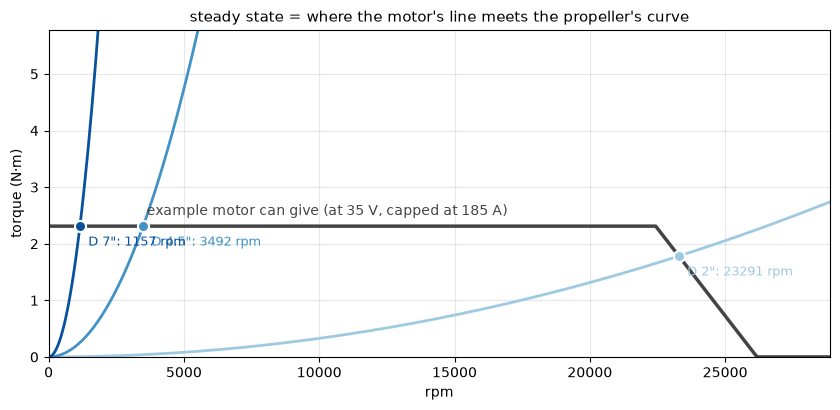

In [56]:
# The mechanism: an example motor's available torque vs the prop's demand.
# Steady state is where the two curves cross.
Kv, R, I0, I_max, V = (CENTER[k] for k in ("Kv", "R", "I0", "I_max", "V"))
Kt = 60 / (2 * math.pi * Kv)
rpm_free = Kv * V
rpm_axis = np.linspace(1, 1.1 * rpm_free, 400)
amps_avail = np.clip((V - rpm_axis / Kv) / R, 0, I_max)
motor_torque = np.maximum(Kt * (amps_avail - I0), 0)

fig, ax = plt.subplots(figsize=(8.5, 4.2))
ax.plot(rpm_axis, motor_torque, color="#444444", lw=2.5)
ax.annotate(f"example motor can give (at {V:g} V, capped at {I_max:g} A)",
            (rpm_axis[len(rpm_axis) // 8], Kt * (I_max - I0)),
            xytext=(0, 8), textcoords="offset points", color="#444444")
for D_in, color in zip(lo_mid_hi(PROP_BOUNDS, "D_in"), SEQ):
    prop_torque = CENTER["K_Q"] * RHO * (rpm_axis / 60) ** 2 * (D_in * M_PER_IN) ** 5
    ax.plot(rpm_axis, prop_torque, color=color, lw=2)
    op = solve(D_in=D_in)
    ax.plot(op["rpm"], op["torque"], "o", color=color, ms=8,
            markeredgecolor="white", markeredgewidth=1.5, zorder=5)
    ax.annotate(f'D {D_in:g}": {op["rpm"]:.0f} rpm', (op["rpm"], op["torque"]),
                xytext=(6, -14), textcoords="offset points", color=color, fontsize=9)
ax.set_xlabel("rpm"); ax.set_ylabel("torque (N·m)")
ax.set_title("steady state = where the motor's line meets the propeller's curve", fontsize=11)
ax.set_xlim(0, rpm_axis[-1]); ax.set_ylim(0, 2.5 * Kt * (I_max - I0))
ax.grid(alpha=0.3)
plt.tight_layout(); plt.show()

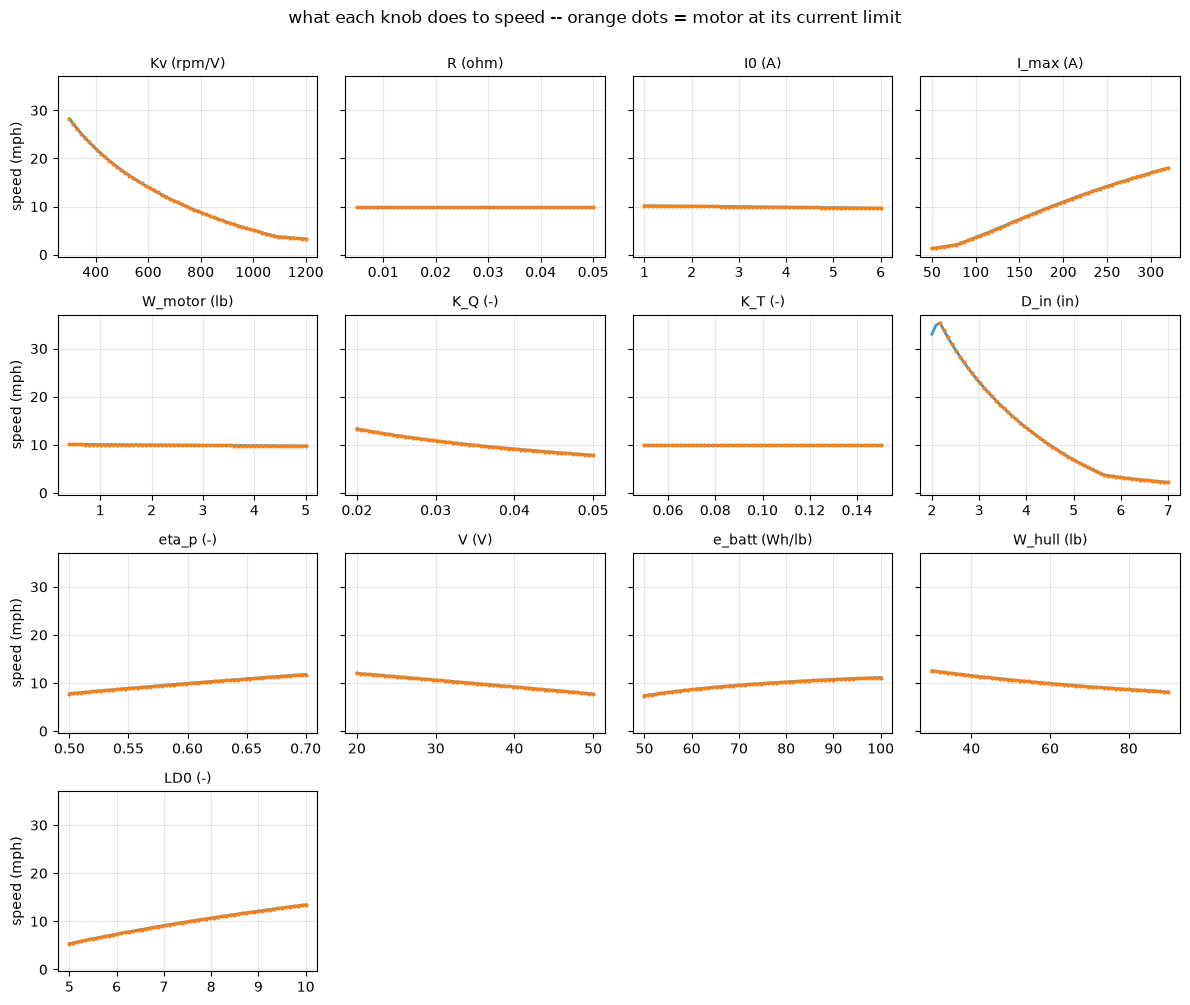

In [57]:
# One panel per input: sweep it across its range with everything else at mid-range (one motor)
SWEEP_KEYS = [k for k in BOUNDS if k != "n_motors"]

fig, axes = plt.subplots(4, 4, figsize=(12, 10), sharey=True)
for key, ax in zip(SWEEP_KEYS, axes.flat):
    lo, hi = BOUNDS[key]
    xs = np.linspace(lo, hi, 60)
    results = [solve(**{key: x}) for x in xs]
    speeds = np.array([r["mph"] for r in results])
    at_limit = np.array([r["limited"] for r in results])
    ax.plot(xs, speeds, color=MID_BLUE, lw=2)
    if at_limit.any():
        ax.plot(xs[at_limit], speeds[at_limit], ".", color="tab:orange", ms=4)
    ax.set_title(f"{key} ({UNITS[key]})", fontsize=10)
    ax.grid(alpha=0.3)
for ax in axes.flat[len(SWEEP_KEYS):]:
    ax.axis("off")
for ax in axes[:, 0]:
    ax.set_ylabel("speed (mph)")
fig.suptitle("what each knob does to speed -- orange dots = motor at its current limit", y=1.0)
plt.tight_layout(); plt.show()

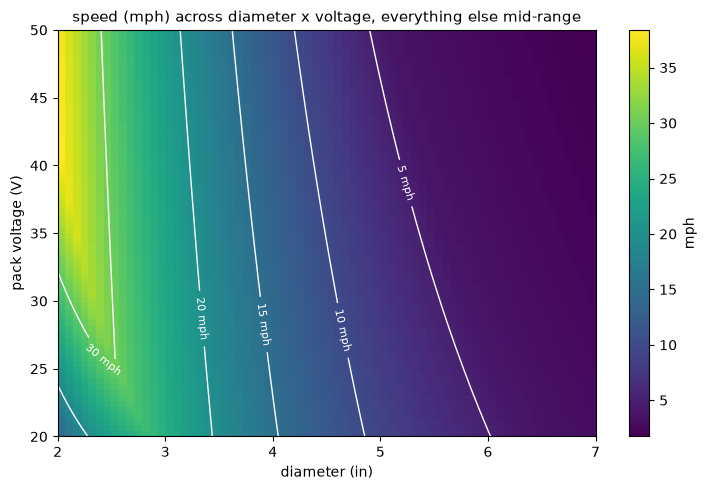

across this map the design asks you to buy pitch between 1.4 and 4.6 in (buyable: 6-14)


In [58]:
# Speed across prop diameter and pack voltage, everything else at mid-range
D_axis = np.linspace(*PROP_BOUNDS["D_in"], 70)
V_axis = np.linspace(*BATT_BOUNDS["V"], 70)
grid = [[solve(D_in=D, V=volts) for D in D_axis] for volts in V_axis]
speed = np.array([[r["mph"] for r in row] for row in grid])

fig, ax = plt.subplots(figsize=(7.5, 5))
im = ax.imshow(speed, origin="lower", aspect="auto", cmap="viridis",
               extent=[D_axis[0], D_axis[-1], V_axis[0], V_axis[-1]])
levels = [lv for lv in (5, 10, 15, 20, 30, 40, 50) if speed.min() < lv < speed.max()]
if levels:
    contours = ax.contour(D_axis, V_axis, speed, levels=levels, colors="white", linewidths=1)
    ax.clabel(contours, fmt="%g mph", fontsize=8)
ax.set_xlabel("diameter (in)"); ax.set_ylabel("pack voltage (V)")
ax.set_title("speed (mph) across diameter x voltage, everything else mid-range", fontsize=11)
fig.colorbar(im, ax=ax, label="mph")
plt.tight_layout(); plt.show()

pitch_grid = np.array([[r["pitch_need"] for r in row] for row in grid])
print(f"across this map the design asks you to buy pitch between "
      f"{pitch_grid.min():.1f} and {pitch_grid.max():.1f} in "
      f"(buyable: {PITCH_BUYABLE[0]:g}-{PITCH_BUYABLE[1]:g})")

## 7. How the variables move together

The map (section 5) shows structure. This shows strength. Sample every input uniformly across its
range, solve the whole model for each sample, and correlate each input with each output. Red
means raising the input raises the output. Blue means raising it lowers the output. White means
it barely matters.

Use it as a cheat-sheet: each column shows which inputs move that output. The `V` row shows its
two roles from the map.

In [59]:
rng = np.random.default_rng(0)
N = 20000
samples = {k: rng.uniform(lo, hi, N) for k, (lo, hi) in BOUNDS.items()}
samples["n_motors"] = rng.integers(1, 3, N).astype(float)  # a discrete choice: one or two

runs = []
for i in range(N):
    runs.append(steady_state(**{k: samples[k][i] for k in BOUNDS}))

OUT = {"speed (mph)": "mph", "battery needed (Ah)": "C", "amps (A)": "I", "weight (lb)": "W"}
outs = {label: np.array([r[key] for r in runs]) for label, key in OUT.items()}

for label, values in outs.items():
    p10, p50, p90 = np.percentile(values, [10, 50, 90])
    print(f"{label:<14} across the whole space:  p10 {p10:6.1f}   median {p50:6.1f}   p90 {p90:6.1f}")

speed (mph)    across the whole space:  p10    1.8   median   12.3   p90   33.6
battery needed (Ah) across the whole space:  p10   49.8   median  165.7   p90  400.0
amps (A)       across the whole space:  p10   89.5   median  231.0   p90  513.4
weight (lb)    across the whole space:  p10  112.3   median  177.1   p90  331.4


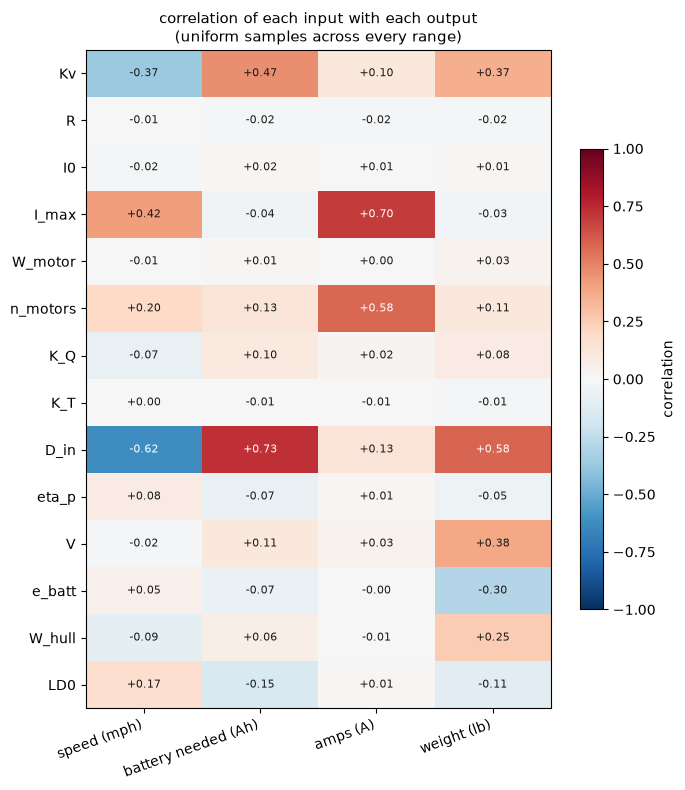

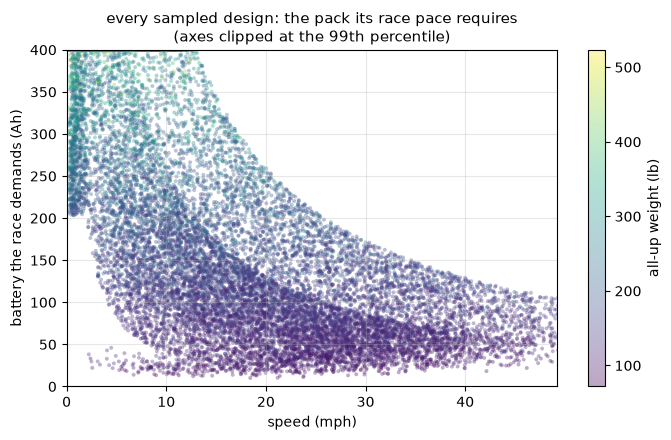

In [60]:
corr = np.array([[np.corrcoef(samples[k], values)[0, 1] for values in outs.values()]
                 for k in BOUNDS])

fig, ax = plt.subplots(figsize=(7, 8))
im = ax.imshow(corr, cmap="RdBu_r", vmin=-1, vmax=1, aspect="auto")
ax.set_xticks(range(len(outs))); ax.set_xticklabels(outs.keys(), rotation=20, ha="right")
ax.set_yticks(range(len(BOUNDS))); ax.set_yticklabels(BOUNDS.keys())
for i in range(len(BOUNDS)):
    for j in range(len(outs)):
        ax.text(j, i, f"{corr[i, j]:+.2f}", ha="center", va="center", fontsize=8,
                color="white" if abs(corr[i, j]) > 0.55 else TEXT)
ax.set_title("correlation of each input with each output\n(uniform samples across every range)",
             fontsize=11)
fig.colorbar(im, ax=ax, label="correlation", shrink=0.7)
plt.tight_layout(); plt.show()

# Every sampled design: speed vs the pack its race pace requires
fig, ax = plt.subplots(figsize=(7, 4.5))
sc = ax.scatter(outs["speed (mph)"], outs["battery needed (Ah)"], c=outs["weight (lb)"],
                cmap="viridis", s=8, alpha=0.35, edgecolors="none")
ax.set_xlim(0, np.percentile(outs["speed (mph)"], 99))
ax.set_ylim(0, np.percentile(outs["battery needed (Ah)"], 99))
ax.set_xlabel("speed (mph)"); ax.set_ylabel("battery the race demands (Ah)")
ax.set_title("every sampled design: the pack its race pace requires\n(axes clipped at the 99th percentile)", fontsize=11)
ax.grid(alpha=0.3)
fig.colorbar(sc, ax=ax, label="all-up weight (lb)")
plt.tight_layout(); plt.show()

## 8. Conclusions: the valid space and the ideal space

Two separate ideas of "good":

- **Valid** means the design meets the requirements (edit them below) and stays inside the
  model's assumptions. The race needs no check, because every pack is sized to the race plus
  reserve by construction. The checks are that the shopping notes are buyable (a real pitch, a
  pack rating under the ceiling) and that the physics holds (thrust covers the water's
  resistance, the motor isn't mostly a heater).
- **Ideal** means the fastest of the valid designs. At constant drive, race time is
  `course / speed`, so the best speed is the best race time.

Everything here is recomputed from the samples. Change a requirement, a sanity bound or any
input range above, re-run, and the conclusions update.

In [61]:
# What we require of the boat (edit freely), and where the model can be trusted
REQS = {"min_speed_mph": 15.0, "max_weight_lb": 160.0}
SANITY = {"min_motor_eff": 0.5}

eff_s = np.array([r["eff"] for r in runs])
thrust_s = np.array([r["thrust_ok"] for r in runs])
crate_s = np.array([r["c_rate_need"] for r in runs])
pitch_s = np.array([r["pitch_need"] for r in runs])
spd = outs["speed (mph)"]
cap_s = outs["battery needed (Ah)"]
wt = outs["weight (lb)"]
amps = outs["amps (A)"]

checks = {
    f"speed >= {REQS['min_speed_mph']:g} mph  (fast enough to bother)": spd >= REQS["min_speed_mph"],
    f"weight <= {REQS['max_weight_lb']:g} lb  (still a small boat)": wt <= REQS["max_weight_lb"],
    f"motor eff >= {SANITY['min_motor_eff']:g}  (less heat than shaft power)": eff_s >= SANITY["min_motor_eff"],
    "prop thrust covers the push-back  (the K_T ceiling)": thrust_s,
    f"pack rating needed <= {C_RATE_MAX:g}C  (a pack you can actually buy)": crate_s <= C_RATE_MAX,
    f"pitch needed in {PITCH_BUYABLE[0]:g}-{PITCH_BUYABLE[1]:g} in  (a thread you can actually buy)":
        (pitch_s >= PITCH_BUYABLE[0]) & (pitch_s <= PITCH_BUYABLE[1]),
}

valid = np.ones(N, dtype=bool)
w = max(len(k) for k in checks)
for name, passed in checks.items():
    print(f"{name:<{w}}   passes {passed.mean():6.1%} alone")
    valid &= passed
print()
print(f"all {len(checks)} at once -> the VALID space: {valid.mean():.1%} of samples ({valid.sum()} designs)")
print(f"(the race needs no check: every pack is sized to {RACE['miles']:g} mi "
      f"+ {RACE['reserve'] - 1:.0%} reserve by construction)")

speed >= 15 mph  (fast enough to bother)                   passes  43.4% alone
weight <= 160 lb  (still a small boat)                     passes  40.9% alone
motor eff >= 0.5  (less heat than shaft power)             passes  16.7% alone
prop thrust covers the push-back  (the K_T ceiling)        passes  15.0% alone
pack rating needed <= 10C  (a pack you can actually buy)   passes 100.0% alone
pitch needed in 6-14 in  (a thread you can actually buy)   passes  17.2% alone

all 6 at once -> the VALID space: 0.8% of samples (154 designs)
(the race needs no check: every pack is sized to 5 mi + 30% reserve by construction)


motor count among valid designs: 20% single, 80% twin


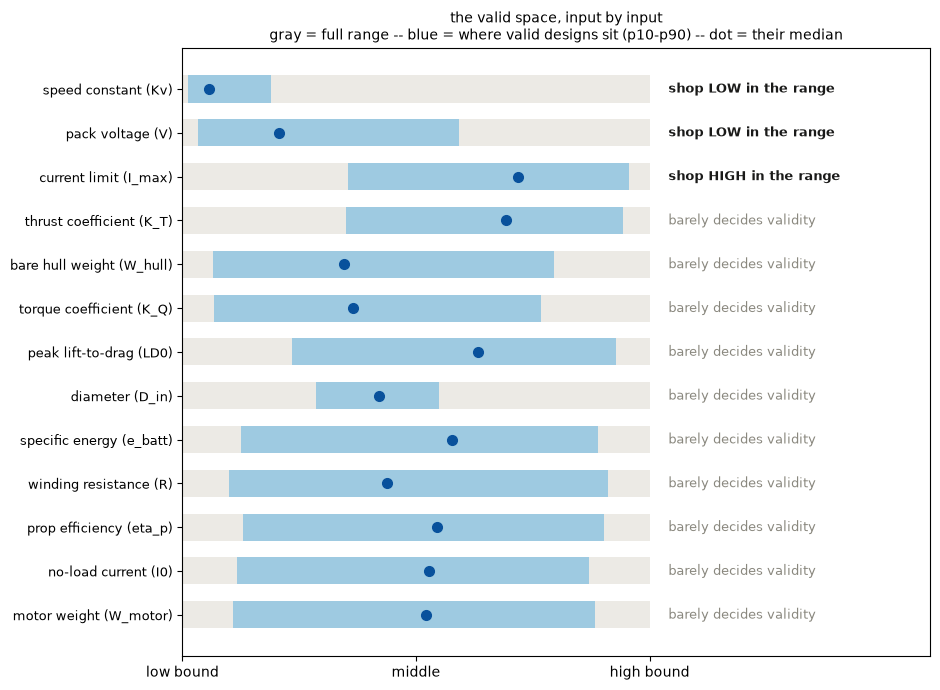

In [62]:
# Where the valid designs sit inside each input's range (the shopping directions)
if not valid.any():
    print("no valid designs: loosen REQS/SANITY or widen the input ranges, then re-run")
else:
    twin = samples["n_motors"][valid] > 1.5
    print(f"motor count among valid designs: {1 - twin.mean():.0%} single, {twin.mean():.0%} twin")

    rows = []
    for k in BOUNDS:
        if k == "n_motors":
            continue
        lo, hi = BOUNDS[k]
        position = (samples[k][valid] - lo) / (hi - lo)  # 0 = low bound, 1 = high bound
        q10, q50, q90 = np.percentile(position, [10, 50, 90])
        rows.append((k, q10, q50, q90, q50 - 0.5))
    rows.sort(key=lambda r: abs(r[4]), reverse=True)  # biggest shift from the middle first

    fig, ax = plt.subplots(figsize=(9.5, 7))
    for i, (k, q10, q50, q90, shift) in enumerate(rows):
        y = len(rows) - 1 - i
        range_bar(ax, y, q10, q50, q90)
        if abs(shift) >= 0.2:
            note = "shop HIGH in the range" if shift > 0 else "shop LOW in the range"
            ax.text(1.04, y, note, va="center", fontsize=9, color=TEXT, fontweight="bold")
        else:
            ax.text(1.04, y, "barely decides validity", va="center", fontsize=9, color=MUTED)
    ax.set_yticks([len(rows) - 1 - i for i in range(len(rows))])
    ax.set_yticklabels([f"{LABELS[k]} ({k})" for k, *_ in rows], fontsize=9)
    ax.set_xlim(0, 1.6); ax.set_xticks([0, 0.5, 1.0])
    ax.set_xticklabels(["low bound", "middle", "high bound"])
    ax.set_title("the valid space, input by input\ngray = full range -- blue = where valid designs sit (p10-p90) -- dot = their median",
                 fontsize=10)
    plt.tight_layout(); plt.show()

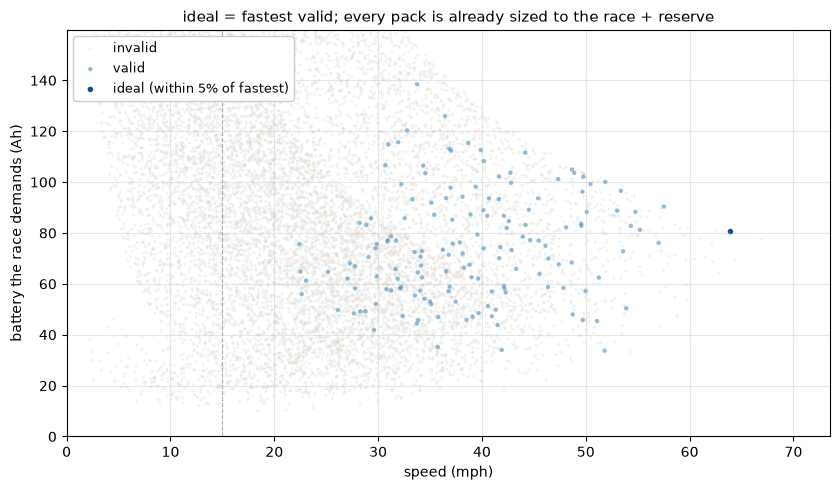

top 3 fastest valid (race = 5 mi at constant drive):
         speed   race time   pack to buy    weight
      63.9 mph     4.7 min         81 Ah    123 lb
      57.5 mph     5.2 min         90 Ah    129 lb
      57.0 mph     5.3 min         76 Ah    143 lb


In [63]:
# The ideal space: the fastest valid designs, and the pack each speed makes you buy
if valid.any():
    fast_cut = 0.95 * spd[valid].max()
    ideal_mask = valid & (spd >= fast_cut)

    fig, ax = plt.subplots(figsize=(8.5, 5))
    ax.scatter(spd[~valid], cap_s[~valid], s=5, color=INVALID_GRAY, alpha=0.3, edgecolors="none", label="invalid")
    ax.scatter(spd[valid], cap_s[valid], s=10, color=MID_BLUE, alpha=0.6, edgecolors="none", label="valid")
    ax.scatter(spd[ideal_mask], cap_s[ideal_mask], s=16, color=DARK_BLUE, edgecolors="none",
               label="ideal (within 5% of fastest)")
    ax.axvline(REQS["min_speed_mph"], color="#aaaaaa", lw=0.8, ls="--")
    ax.set_xlim(0, spd[valid].max() * 1.15)
    ax.set_ylim(0, np.percentile(cap_s[valid], 99) * 1.3)
    ax.set_xlabel("speed (mph)"); ax.set_ylabel("battery the race demands (Ah)")
    ax.set_title("ideal = fastest valid; every pack is already sized to the race + reserve", fontsize=11)
    ax.legend(loc="upper left", fontsize=9, framealpha=1); ax.grid(alpha=0.3)
    plt.tight_layout(); plt.show()

    top3 = np.argsort(-np.where(valid, spd, -np.inf))[:3]
    print(f"top 3 fastest valid (race = {RACE['miles']:g} mi at constant drive):")
    print(f"{'':>4}{'speed':>10}{'race time':>12}{'pack to buy':>14}{'weight':>10}")
    for i in top3:
        print(f"{'':>4}{spd[i]:>6.1f} mph{60 * RACE['miles'] / spd[i]:>8.1f} min"
              f"{cap_s[i]:>11.0f} Ah{wt[i]:>7.0f} lb")

## 9. the SSS catalog for product

This section runs every winding of every SSS motor on the supplier sheet (`sss_motors.csv`)
through the same model and the same validity checks as section 8. The motor's numbers (`Kv`,
`R`, `I0`, `I_max` and weight) come from the sheet instead of a range. Prop, battery and hull
are sampled from their ranges as before. The sheet adds two rules:

- Pack voltage is capped at the winding's `v_max`, so you only buy a pack the motor can take.
- A combo that spins past the winding's `max_rpm` is invalid.

A **combo** is one winding paired with one sampled prop, battery and hull. It is valid if it
passes every section 8 check plus `max_rpm`. A winding's "valid %" is the share of the
prop/battery/hull space where it stays valid. The winding at the top of the table is the most
forgiving one, not necessarily the fastest: it stays valid across the widest variety of props,
batteries and hulls. Section 10 finds the best designs (the ideal set), and the best winding
there can be a different one.

In [64]:
with open("sss_motors.csv") as f:
    CATALOG = [
        dict(name=f"{row['motor']} {row['winding']}", Kv=float(row["kv_rpm_per_v"]),
             R=float(row["r_ohm"]), I0=float(row["i0_a_at_11v"]), I_max=float(row["i_max_a"]),
             v_max=float(row["v_max_v"]), max_rpm=float(row["max_rpm"]),
             W_motor=float(row["weight_g"]) / G_PER_LB)
        for row in csv.DictReader(f)
    ]
print(f"{len(CATALOG)} windings on the SSS sheet")

# Prop, battery and hull inputs are sampled once and reused for every winding
NON_MOTOR = [k for k in BOUNDS if k not in MOTOR_BOUNDS]
N_COMBOS = 2000
rng2 = np.random.default_rng(1)
sub = {k: rng2.uniform(*BOUNDS[k], N_COMBOS) for k in NON_MOTOR}
sub["n_motors"] = rng2.integers(1, 3, N_COMBOS).astype(float)


def run_winding(m):
    """Run one winding against every sampled prop/battery/hull combo."""
    results = []
    for i in range(N_COMBOS):
        p = {k: sub[k][i] for k in NON_MOTOR}
        p["n_motors"] = sub["n_motors"][i]
        p["V"] = min(p["V"], m["v_max"])  # buy a pack the winding can take
        r = steady_state(Kv=m["Kv"], R=m["R"], I0=m["I0"], I_max=m["I_max"], W_motor=m["W_motor"], **p)
        r["ok"] = (r["mph"] >= REQS["min_speed_mph"]
                   and r["W"] <= REQS["max_weight_lb"]
                   and r["eff"] >= SANITY["min_motor_eff"]
                   and PITCH_BUYABLE[0] <= r["pitch_need"] <= PITCH_BUYABLE[1]
                   and r["thrust_ok"]
                   and r["c_rate_need"] <= C_RATE_MAX
                   and r["rpm"] <= m["max_rpm"])
        r["inputs"] = p  # the non-motor inputs actually used (V after the v_max cap)
        results.append(r)
    return results


summary, CAT_VALID = [], []
for m in CATALOG:
    results = run_winding(m)
    ok = [r for r in results if r["ok"]]
    for r in ok:
        CAT_VALID.append(dict(name=m["name"], mph=r["mph"], minutes=r["minutes"], inputs=r["inputs"]))
    summary.append(dict(m=m, frac=len(ok) / N_COMBOS,
                        best_mph=max((r["mph"] for r in ok), default=float("nan")),
                        best_min=max((r["minutes"] for r in ok), default=float("nan"))))
summary.sort(key=lambda s: -s["frac"])

n_zero = sum(1 for s in summary if s["frac"] == 0)
print(f"windings with no valid combo at all: {n_zero} of {len(summary)}")
print()
print(f"{'winding':<24}{'Kv':>6}{'v_max':>7}{'I_max':>7}   {'valid':>6}  {'best mph':>9}{'best min':>9}")
for s in summary[:12]:
    m = s["m"]
    print(f"{m['name']:<24}{m['Kv']:>6.0f}{m['v_max']:>7.0f}{m['I_max']:>7.0f}   "
          f"{s['frac']:>6.1%}  {s['best_mph']:>9.1f}{s['best_min']:>9.1f}")
print()
print(f"(for scale: random motors drawn from the section-1 ranges are {valid.mean():.1%} valid)")

263 windings on the SSS sheet
windings with no valid combo at all: 214 of 263

winding                     Kv  v_max  I_max    valid   best mph best min
SSS 56154-V2 12Y           165    150    133    20.3%       53.5     25.7
SSS 56154-V2 11Y           180    138    145    19.5%       53.1     24.3
SSS 56154-V2 10Y           200    125    160    18.9%       54.8     22.0
SSS 56154-V2 9Y            220    112    178    16.8%       56.9     20.2
SSS 56154-V2 8Y            250     99    202    14.7%       62.8     20.9
SSS 56133-V2 11Y           200    170    100    13.9%       52.4     24.0
SSS 56154-V2 7Y            280     88    227    13.4%       64.0     17.4
SSS 56133-V2 10Y           230    155    108    11.2%       52.4     25.8
SSS 56154-V2 6Y            330     75    266     9.9%       63.1     16.7
SSS 56123-V1 12Y           230    155     95     9.4%       49.1     25.2
SSS 56123-V2 12Y           230    155     95     9.4%       49.0     25.2
SSS 56133-V2 9Y            270   

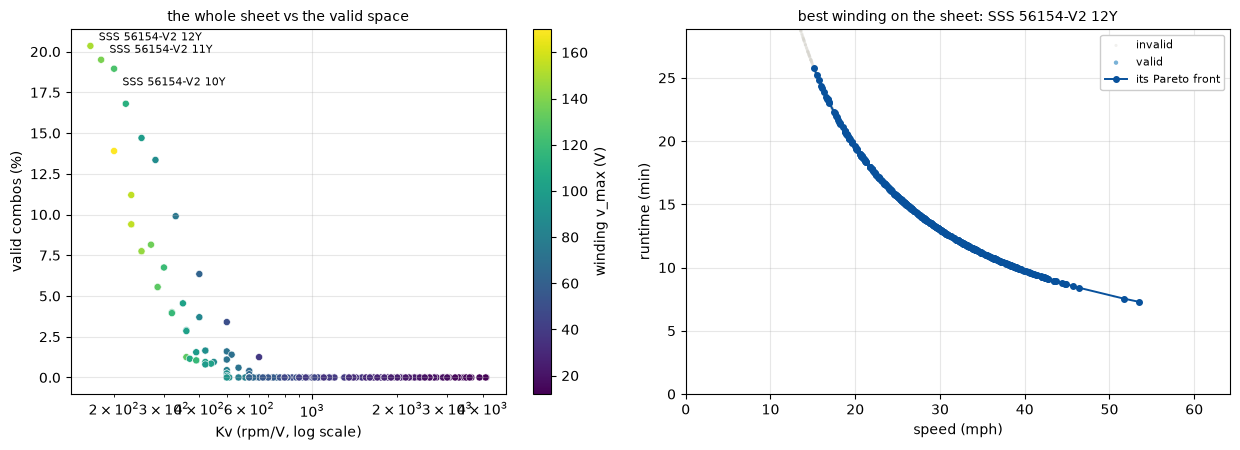

In [65]:
def pareto_front(mph, minutes):
    """Indices of points that no other point beats on both speed and runtime, fastest first."""
    front, best_minutes = [], -np.inf
    for i in np.argsort(-mph):
        if minutes[i] > best_minutes:
            front.append(i)
            best_minutes = minutes[i]
    return front


fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12.5, 4.6))

# Left: the whole sheet. Each dot is a winding, colored by its v_max.
kv = np.array([s["m"]["Kv"] for s in summary])
valid_pct = np.array([s["frac"] for s in summary]) * 100
v_max = np.array([s["m"]["v_max"] for s in summary])
sc = ax1.scatter(kv, valid_pct, c=v_max, cmap="viridis", s=26, edgecolors="white", linewidths=0.4)
ax1.set_xscale("log")
for s, offset in zip(summary[:3], [(6, 4), (6, 5), (6, -12)]):
    ax1.annotate(s["m"]["name"], (s["m"]["Kv"], s["frac"] * 100),
                 xytext=offset, textcoords="offset points", fontsize=8)
ax1.set_xlabel("Kv (rpm/V, log scale)"); ax1.set_ylabel("valid combos (%)")
ax1.set_title("the whole sheet vs the valid space", fontsize=10)
ax1.grid(alpha=0.3)
fig.colorbar(sc, ax=ax1, label="winding v_max (V)")

# Right: speed vs runtime for every combo of the top winding
best = summary[0]["m"]
results = run_winding(best)
mphs = np.array([r["mph"] for r in results])
mins = np.array([r["minutes"] for r in results])
ok_mask = np.array([r["ok"] for r in results])
ax2.scatter(mphs[~ok_mask], mins[~ok_mask], s=5, color=INVALID_GRAY, alpha=0.35, edgecolors="none", label="invalid")
if ok_mask.any():
    ax2.scatter(mphs[ok_mask], mins[ok_mask], s=10, color=MID_BLUE, alpha=0.7, edgecolors="none", label="valid")
    front = pareto_front(mphs[ok_mask], mins[ok_mask])
    ax2.plot(mphs[ok_mask][front], mins[ok_mask][front], "-o", color=DARK_BLUE, ms=4, lw=1.4,
             label="its Pareto front")
    ax2.set_ylim(0, mins[ok_mask].max() * 1.12)
ax2.set_xlim(0, (mphs[ok_mask].max() if ok_mask.any() else mphs.max()) * 1.2)
ax2.set_xlabel("speed (mph)"); ax2.set_ylabel("runtime (min)")
ax2.set_title(f"best winding on the sheet: {best['name']}", fontsize=10)
ax2.legend(loc="upper right", fontsize=8, framealpha=1)
ax2.grid(alpha=0.3)
plt.tight_layout(); plt.show()

## 10. Are the ideal designs pressed against our bounds?

Every range in this notebook is a guess with a low end and a high end. If the ideal designs pile
up against one end of a range, that bound is making the choice, not the physics. Either widen the
bound (if it was arbitrary) or firm it up (if it's a real limit, in which case "buy the bound" is
the conclusion).

Ideal here means the fastest valid combos: the top 50, or everything within 5% of the best speed
if that is more, pooled across every SSS winding. That gives the best race pace using only motors
we can buy.

5053 valid catalog combos -> ideal = the 50 fastest (64.7 down to 56.4 mph; best race 4.6 min)
windings in the ideal set: SSS 56154-V2 4Y (11), SSS 56154-V2 5Y (9), SSS 56154-V2 7Y (9), SSS 56154-V2 3Y (8), SSS 56154-V2 6Y (8), SSS 56154-V2 8Y (3) ...
motor count in the ideal set: 0% single, 100% twin



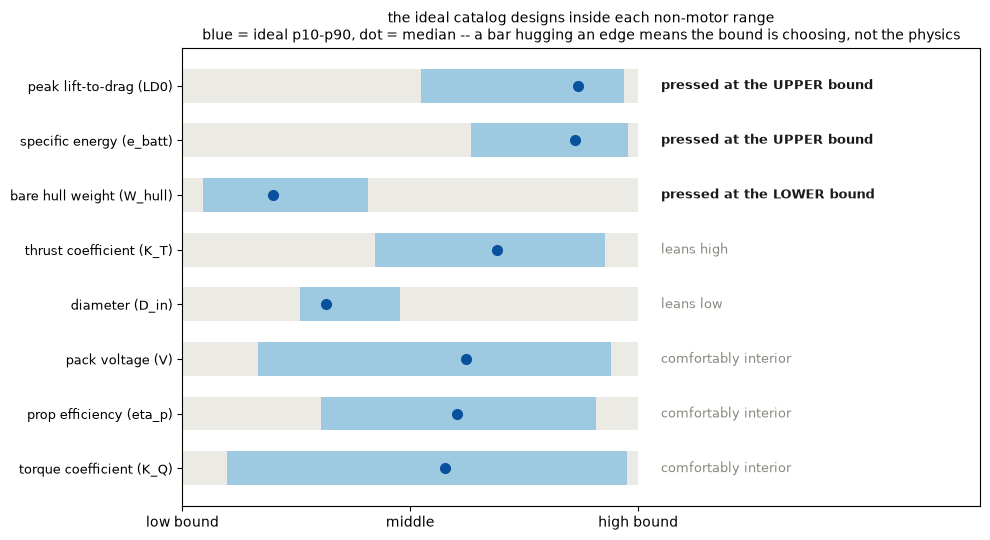


peak lift-to-drag (LD0): ideal median 9.34 - -> hugging the upper bound (5..10): widen it if it was a guess, or buy the bound if it's real
specific energy (e_batt): ideal median 93.1 Wh/lb -> hugging the upper bound (50..100): widen it if it was a guess, or buy the bound if it's real
bare hull weight (W_hull): ideal median 41.9 lb -> hugging the lower bound (30..90): widen it if it was a guess, or buy the bound if it's real


In [66]:
mph_all = np.array([d["mph"] for d in CAT_VALID])
best_mph = mph_all.max()
n_ideal = max(50, int((mph_all >= 0.95 * best_mph).sum()))  # enough designs for stable percentiles
order = np.argsort(-mph_all)[:n_ideal]
IDEAL = [CAT_VALID[i] for i in order]
slowest_ideal = mph_all[order[-1]]
print(f"{len(CAT_VALID)} valid catalog combos -> ideal = the {len(IDEAL)} fastest "
      f"({best_mph:.1f} down to {slowest_ideal:.1f} mph; best race {60 * RACE['miles'] / best_mph:.1f} min)")

mix = Counter(d["name"] for d in IDEAL).most_common()
print("windings in the ideal set: " + ", ".join(f"{n} ({c})" for n, c in mix[:6])
      + (" ..." if len(mix) > 6 else ""))
twin_ideal = np.array([d["inputs"]["n_motors"] for d in IDEAL]) > 1.5
print(f"motor count in the ideal set: {1 - twin_ideal.mean():.0%} single, {twin_ideal.mean():.0%} twin")
print()

# Where the ideal designs sit inside each non-motor range (0 = low bound, 1 = high bound)
rows = []
for k in NON_MOTOR:
    lo, hi = BOUNDS[k]
    position = np.array([(d["inputs"][k] - lo) / (hi - lo) for d in IDEAL])
    q10, q50, q90 = np.percentile(position, [10, 50, 90])
    rows.append((k, q10, q50, q90))
rows.sort(key=lambda r: abs(r[2] - 0.5), reverse=True)


def verdict(q50):
    """Describe where the median sits in the range. Returns (text, pressed against a bound)."""
    if q50 >= 0.8: return "pressed at the UPPER bound", True
    if q50 <= 0.2: return "pressed at the LOWER bound", True
    if q50 >= 0.65: return "leans high", False
    if q50 <= 0.35: return "leans low", False
    return "comfortably interior", False


fig, ax = plt.subplots(figsize=(10, 5.5))
for i, (k, q10, q50, q90) in enumerate(rows):
    y = len(rows) - 1 - i
    range_bar(ax, y, q10, q50, q90)
    text, pressed = verdict(q50)
    ax.text(1.05, y, text, va="center", fontsize=9,
            color=TEXT if pressed else MUTED,
            fontweight="bold" if pressed else "normal")
ax.set_yticks([len(rows) - 1 - i for i in range(len(rows))])
ax.set_yticklabels([f"{LABELS[k]} ({k})" for k, *_ in rows], fontsize=9)
ax.set_xlim(0, 1.75); ax.set_xticks([0, 0.5, 1.0])
ax.set_xticklabels(["low bound", "middle", "high bound"])
ax.set_title("the ideal catalog designs inside each non-motor range\nblue = ideal p10-p90, dot = median -- a bar hugging an edge means the bound is choosing, not the physics",
             fontsize=10)
plt.tight_layout(); plt.show()

print()
any_pressed = False
for k, q10, q50, q90 in rows:
    text, pressed = verdict(q50)
    if pressed:
        any_pressed = True
        lo, hi = BOUNDS[k]
        median_value = lo + q50 * (hi - lo)
        side = "upper" if q50 >= 0.8 else "lower"
        print(f"{LABELS[k]} ({k}): ideal median {median_value:.3g} {UNITS[k]} -> hugging the {side} "
              f"bound ({lo:g}..{hi:g}): widen it if it was a guess, or buy the bound if it's real")
if not any_pressed:
    print("no input is pressed against a bound: the ranges are wide enough that the physics is choosing")

In [67]:
# Shopping lists: three concrete ideal designs, each best at something different
candidates = []
for d in IDEAL:
    winding = next(c for c in CATALOG if c["name"] == d["name"])
    result = steady_state(Kv=winding["Kv"], R=winding["R"], I0=winding["I0"], I_max=winding["I_max"],
                          W_motor=winding["W_motor"], **d["inputs"])
    candidates.append((d, winding, result))

picks = {
    "fastest ideal":    max(candidates, key=lambda c: c[2]["mph"]),
    "lightest battery": min(candidates, key=lambda c: c[2]["W_batt"]),
    "most efficient":   max(candidates, key=lambda c: c[2]["eff"]),
}
designs = [d for d, m, r in picks.values()]
windings = [m for d, m, r in picks.values()]
results = [r for d, m, r in picks.values()]

LABEL_WIDTH = 34
COLUMN_WIDTH = 20


def row(label, values):
    print(f"{label:<{LABEL_WIDTH}}" + "".join(f"{v:>{COLUMN_WIDTH}}" for v in values))


def section(title):
    print()
    print(f"-- {title} " + "-" * (LABEL_WIDTH + COLUMN_WIDTH * len(picks) - len(title) - 4))


row("", picks)

section("motor (buy this winding)")
row("SSS winding", [d["name"].replace("SSS ", "") for d in designs])
row("number of motors", [f"{d['inputs']['n_motors']:.0f}" for d in designs])
row("speed constant Kv (rpm/V)", [f"{m['Kv']:g}" for m in windings])
row("current limit I_max (A)", [f"{m['I_max']:g}" for m in windings])
row("winding max voltage (V)", [f"{m['v_max']:g}" for m in windings])
row("motor weight (lb)", [f"{m['W_motor']:.1f}" for m in windings])

section("propeller")
for k in PROP_BOUNDS:
    row(f"{LABELS[k]} ({k}, {UNITS[k]})", [f"{d['inputs'][k]:.3g}" for d in designs])
row("pitch to BUY (in)", [f"{r['pitch_need']:.1f}" for r in results])

section("battery")
for k in BATT_BOUNDS:
    row(f"{LABELS[k]} ({k}, {UNITS[k]})", [f"{d['inputs'][k]:.3g}" for d in designs])
row("capacity to BUY (Ah)", [f"{r['C']:.0f}" for r in results])
row("pack weight (lb)", [f"{r['W_batt']:.0f}" for r in results])
row("rating needed (C-rate)", [f"{r['c_rate_need']:.1f}C (max {C_RATE_MAX:g}C)" for r in results])

section("hull")
for k in HULL_BOUNDS:
    row(f"{LABELS[k]} ({k}, {UNITS[k]})", [f"{d['inputs'][k]:.3g}" for d in designs])

section("what you get")
row("speed (mph)", [f"{r['mph']:.1f}" for r in results])
row("steady current, pack (A)", [f"{r['I']:.0f}" for r in results])
row("volts actually needed (V)",
    [f"{r['rpm'] / m['Kv'] + r['I_1'] * m['R']:.1f}" for m, r in zip(windings, results)])
row("race time (min)", [f"{60 * RACE['miles'] / r['mph']:.1f}" for r in results])
row("battery used in race (Ah)", [f"{r['I'] * RACE['miles'] / r['mph']:.0f}" for r in results])
row("all-up weight (lb)", [f"{r['W']:.0f}" for r in results])
row("motor efficiency", [f"{r['eff']:.2f}" for r in results])
row("operating L/D (solved)", [f"{r['LD_op']:.1f}" for r in results])
row("push available vs needed (lbf)", [f"{r['t_avail_lbf']:.0f} vs {r['R_lbf']:.0f}" for r in results])

section("if you just keep driving at this speed")
row("full runtime on this battery (min)", [f"{r['minutes']:.0f}" for r in results])
row("distance that covers (mi)", [f"{r['minutes'] / 60 * r['mph']:.0f}" for r in results])

                                         fastest ideal    lightest battery      most efficient

-- motor (buy this winding) ------------------------------------------------------------------
SSS winding                                56154-V2 5Y         56154-V2 9Y         56154-V2 7Y
number of motors                                     2                   2                   2
speed constant Kv (rpm/V)                          400                 220                 280
current limit I_max (A)                            320                 178                 227
winding max voltage (V)                             62                 112                  88
motor weight (lb)                                  3.9                 3.9                 3.9

-- propeller ---------------------------------------------------------------------------------
torque coefficient (K_Q, -)                     0.0241              0.0498              0.0241
thrust coefficient (K_T, -)                     

## What is not modeled

1. **The prop's real curve.** `K_Q`, `K_T` and `η_p` are held constant per prop. In reality all
   three come from the same measured series data and change with pitch and with advance (how
   fast the boat is already moving relative to the prop). The constant-`K_T` thrust ceiling is
   in. The full curves `K_T(J)` and `K_Q(J)`, with slip and `η_p` as outputs, are the next step.
2. **Pack voltage sag.** A loaded pack loses volts under heavy draw. The discharge limit is
   handled as a printed requirement (the C-rating the pack must carry), with a buyability
   ceiling as a validity check.
3. **The hump.** `L/D(v)` covers the boat once it is on plane. Getting onto plane (the drag hump
   around 10 mph) is not modeled, so slow solutions are optimistic.
4. **The sheet's power ratings.** The SSS CSV also has continuous and peak power ratings. They
   are not enforced yet (motor weight is).